# Random Forest

In [1]:
import sys
import json
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (p / "pyproject.toml").is_file())
MODULE_PATH = PROJECT_ROOT / "random_forest" / "random_forest_genres.py"
MODEL_PATH = PROJECT_ROOT / "models" / "random_forest.json"

spec = importlib.util.spec_from_file_location("random_forest_genres", MODULE_PATH)
random_forest_genres = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = random_forest_genres
spec.loader.exec_module(random_forest_genres)
RandomForestFromJSON = random_forest_genres.RandomForestFromJSON

with open(MODEL_PATH, encoding="utf-8") as f:
    results = json.load(f)

rf_model = RandomForestFromJSON(results["model"])
rf_model.classes_ = np.asarray(rf_model.classes, dtype=object)

df = pd.read_csv(PROJECT_ROOT / results["metadata"]["data_path"])
id_parts = df["filename"].astype(str).str.extract(results["config"]["song_id_pattern"])
df["song_id"] = id_parts[0].str.lower() + id_parts[1]

test_df = df[df["song_id"].isin(results["split"]["test_songs"])].reset_index(drop=True)
X_test = test_df[rf_model.feature_names]
y_test = test_df["label"]

print(f"Project root: {PROJECT_ROOT}")
print(f"Holdout fragments: {len(X_test)} | Songs: {test_df['song_id'].nunique()}")
print(f"Holdout accuracy: {(rf_model.predict(X_test) == y_test).mean():.4f} | Stored: {results['holdout']['accuracy']:.4f}")

Project root: C:\PrograPhil\Jazz-Inador
Holdout fragments: 2000 | Songs: 200


Holdout accuracy: 0.7135 | Stored: 0.7135


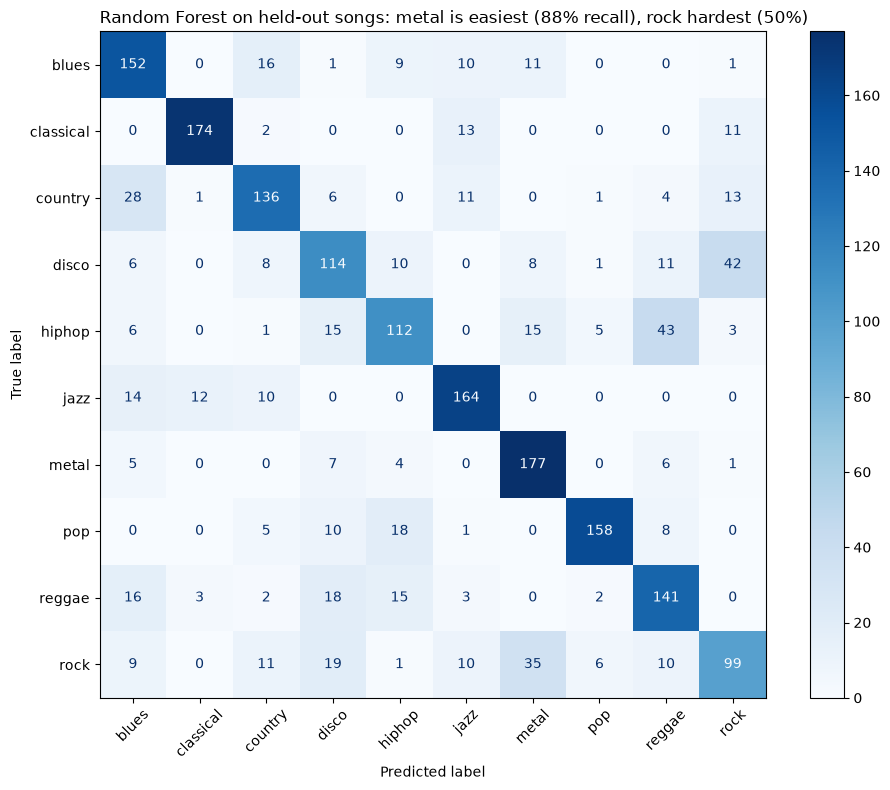

In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = rf_model.predict(X_test)
labels = rf_model.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=True,
)
MODEL_NAME = "Random Forest"
recalls = cm.diagonal() / cm.sum(axis=1)
ax.set_title(
    f"{MODEL_NAME} on held-out songs: {labels[recalls.argmax()]} is easiest ({recalls.max():.0%} recall), "
    f"{labels[recalls.argmin()]} hardest ({recalls.min():.0%})",
    loc="left",
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

In [3]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score

y_pred = rf_model.predict(X_test)
labels = rf_model.classes_

cm = confusion_matrix(y_test, y_pred, labels=labels)
total = cm.sum()
tp = np.diag(cm)
fp = cm.sum(axis=0) - tp
fn = cm.sum(axis=1) - tp
tn = total - tp - fp - fn

metrics = pd.DataFrame(
    {
        "accuracy": (tp + tn) / total,
        "precision": precision_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
        "recall": recall_score(y_test, y_pred, labels=labels, average=None, zero_division=0),
        "support": cm.sum(axis=1),
    },
    index=labels,
)
metrics.index.name = "genre"

display(metrics.round(4))
print(f"Overall accuracy: {accuracy_score(y_test, y_pred):.4f}")

,accuracy,precision,recall,support
genre,,,,
blues,0.9340,0.6441,0.760,200
classical,0.9790,0.9158,0.870,200
country,0.9405,0.7120,0.680,200
disco,0.9190,0.6000,0.570,200
hiphop,0.9275,0.6627,0.560,200
jazz,0.9580,0.7736,0.820,200
metal,0.9540,0.7195,0.885,200
pop,0.9715,0.9133,0.790,200
reggae,0.9295,0.6323,0.705,200


Overall accuracy: 0.7135
